# Tumour / normal sample QC from aligned reads at a SNP panel

**Identity, contamination, tumour-in-normal and tumour content — before any variant is called**

A paired tumour / normal sequencing batch can be wrong in ways that no
downstream caller will notice. Somatic calling *assumes* that the normal
belongs to the same person as the tumour, that neither library carries
DNA of another sample, that the normal is free of tumour cells, and that
the tumour actually contains tumour. When one of these assumptions breaks:

- a **sample swap** (the wrong normal submitted with a tumour) turns
  thousands of germline SNPs into false "somatic" mutations;
- **cross-sample contamination** at a few percent creates low-VAF
  artefacts that look like sub-clonal mutations;
- **tumour-in-normal (TiN)** contamination — tumour cells in the
  "normal" blood or adjacent tissue — makes the caller *reject* real
  somatic mutations because they are also seen in the normal;
- a **low-tumour-content** biopsy yields a flat profile and a false
  "no driver found" result.

All four can be settled from **one cheap measurement**: the read counts
of the reference and alternative allele at a panel of common germline
SNPs. At each site a diploid sample is homozygous (allele fraction ≈ 0 or 1)
or heterozygous (≈ 0.5); deviations from these three states, and
agreement between samples, carry the whole QC signal:

| Question | Signal at the SNP panel | Function |
|---|---|---|
| Do two files come from the same person? | genotype discordance between samples | `sample_genotype_concordance`, `resolve_sample_relationships` |
| Is a library contaminated, and by whom? | minority-allele reads at its homozygous sites that follow another sample's genotype | `estimate_cross_sample_contamination` |
| Has the tumour lost an allele (LOH), how pure is it? | folded allele fraction of the tumour vs the normal at normal-heterozygous sites | `tumor_normal_allelic_imbalance` |
| Does the normal contain tumour? | the normal's heterozygous AF shifted toward the tumour's retained allele inside the tumour's LOH regions | `tumor_in_normal_shift` |
| Is a library technically odd? | read length / MAPQ / duplicate / modified-base batch z-scores | `bam_read_summary` |
| All of the above, one row per finding | | `tumor_normal_batch_qc` |

The starting point is `ov.genetics.snp_allele_counts`, a pysam pileup
of every BAM/CRAM at the panel. Nothing in the chain is tied to a
platform or panel: every cut-off is a genotype-state definition or a
significance level.

**What this tutorial does.** Real tumour/normal BAMs are controlled
access, so we **simulate** a small but realistic batch inside the
notebook: a reference genome, a 600-SNP targeted panel, and 13 aligned
BAM files (6 patients × tumour/normal plus one re-sequenced library). We
plant six problems with a known answer, run the QC chain, and check
every finding against the truth.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pysam
import omicverse as ov

ov.plot_set()
rng = np.random.default_rng(2024)
print('pysam', pysam.__version__)

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 PyTorch not available - GPU detection skipped

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.

pysam 0.23.3


## 1. Simulate a reference, a SNP panel and target intervals

The panel mimics a typical sample-tracking / identity panel (e.g. the
NGSCheckMate or Conpair site lists): **common bi-allelic SNPs**
(minor-allele frequency 0.2–0.5, so most individuals differ at many of
them) spread over several chromosomes. We use four 60-kb "chromosomes",
each with two target intervals (a `p` and a `q` arm) of 75 SNPs spaced
250 bp apart. The arms are the **regions** in which allelic imbalance is
summarised later, exactly like arm-level copy-number segments.

In [2]:
outdir = 'sampleqc_data'
os.makedirs(f'{outdir}/bams', exist_ok=True)

CHROMS = ['chr1', 'chr2', 'chr3', 'chr4']
SPACING, N_PER_ARM, FLANK, GAP = 250, 75, 2000, 5000
arm_len = SPACING * N_PER_ARM

REF, site_rows, bed_rows = {}, [], []
for c in CHROMS:
    L = 2 * FLANK + 2 * arm_len + GAP
    REF[c] = ''.join(rng.choice(list('ACGT'), L))
    for k, arm in enumerate(['p', 'q']):
        start = FLANK + k * (arm_len + GAP)
        bed_rows.append((c, start, start + arm_len, f'{c}{arm}'))
        for j in range(N_PER_ARM):
            pos = start + j * SPACING + SPACING // 2          # 1-based position
            ref = REF[c][pos - 1]
            alt = rng.choice([b for b in 'ACGT' if b != ref])
            site_rows.append((c, pos, ref, alt, f'{c}{arm}'))

sites = pd.DataFrame(site_rows, columns=['chrom', 'pos', 'ref', 'alt', 'region'])
targets = pd.DataFrame(bed_rows, columns=['chrom', 'start', 'end', 'name'])

# population allele frequency of the ALT allele: common SNPs, ALT minor or major at random
maf = rng.uniform(0.2, 0.5, len(sites))
sites['pop_alt_freq'] = np.where(rng.random(len(sites)) < 0.5, maf, 1 - maf)

# write the reference, the panel VCF (bgzipped + tabix) and the BED, as a real pipeline would have them
with open(f'{outdir}/ref.fa', 'w') as fh:
    for c in CHROMS:
        fh.write(f'>{c}\n' + '\n'.join(REF[c][i:i + 60] for i in range(0, len(REF[c]), 60)) + '\n')
pysam.faidx(f'{outdir}/ref.fa')
with open(f'{outdir}/panel.vcf', 'w') as fh:
    fh.write('##fileformat=VCFv4.2\n')
    for c in CHROMS:
        fh.write(f'##contig=<ID={c},length={len(REF[c])}>\n')
    fh.write('##INFO=<ID=AF,Number=A,Type=Float,Description="Population ALT frequency">\n')
    fh.write('#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n')
    for r in sites.itertuples():
        fh.write(f'{r.chrom}\t{r.pos}\trs{r.Index:05d}\t{r.ref}\t{r.alt}\t.\tPASS\tAF={r.pop_alt_freq:.3f}\n')
pysam.tabix_index(f'{outdir}/panel.vcf', preset='vcf', force=True)
targets.to_csv(f'{outdir}/targets.bed', sep='\t', header=False, index=False)

print(f'{len(sites)} panel SNPs in {len(targets)} target intervals on {len(CHROMS)} contigs')
targets

600 panel SNPs in 8 target intervals on 4 contigs


  chrom  start    end   name
0  chr1   2000  20750  chr1p
1  chr1  25750  44500  chr1q
2  chr2   2000  20750  chr2p
3  chr2  25750  44500  chr2q
4  chr3   2000  20750  chr3p
5  chr3  25750  44500  chr3q
6  chr4   2000  20750  chr4p
7  chr4  25750  44500  chr4q

## 2. Simulate six patients — and plant six problems

Each of six individuals `I1`–`I6` gets germline genotypes drawn from the
panel allele frequencies (Hardy–Weinberg). Each **tumour** has
copy-neutral loss of heterozygosity (LOH) on two or three arms — at
every heterozygous SNP of those arms the tumour cells keep one allele —
and a **purity** (fraction of tumour cells); the remaining cells are
normal, so the tumour library's allele fraction is
`purity × tumour-cell AF + (1 − purity) × germline AF`.

Then the batch is broken, on purpose, in six ways:

| Planted problem | Truth |
|---|---|
| **Sample swap** | the files submitted as `P2-N` and `P3-N` are each other's normals (individual `I3` and `I2`) |
| **Cross-sample contamination** | `P4-T` contains **5 %** DNA of `P6-N` (another individual) |
| **Tumour-in-normal** | `P5-N` contains **10 %** of the `P5-T` tumour sample |
| **Low tumour content** | `P6-T` has purity **0.15** — essentially a normal-like biopsy |
| **Same-individual duplicate** | `P1-N-rerun` is a second library of `P1-N` (not in the manifest) |
| **Library outlier** | `P4-N` is degraded: reads ~75 bp instead of ~145 bp |

`P1` is the clean control: correct pairing, no contamination, purity 0.8.

In [3]:
inds = [f'I{i}' for i in range(1, 7)]
germ = {i: rng.binomial(2, sites['pop_alt_freq'].values) / 2 for i in inds}      # 0, 0.5, 1

LOH = {'I1': ['chr1p', 'chr3q'], 'I2': ['chr2p', 'chr4q', 'chr1q'], 'I3': ['chr3p', 'chr2q'],
       'I4': ['chr4p', 'chr1q'], 'I5': ['chr1p', 'chr2q', 'chr4p'], 'I6': ['chr3q', 'chr4q']}
PURITY = {'I1': 0.80, 'I2': 0.75, 'I3': 0.85, 'I4': 0.80, 'I5': 0.85, 'I6': 0.15}

tumour_af = {}
for i in inds:
    cell = germ[i].copy()
    loh = sites['region'].isin(LOH[i]).values & (germ[i] == 0.5)
    cell[loh] = rng.choice([0.0, 1.0], loh.sum())                 # retained allele per LOH locus
    tumour_af[i] = PURITY[i] * cell + (1 - PURITY[i]) * germ[i]

# what DNA is really inside each file: {(tissue, individual): fraction}
COMPOSITION = {
    'P1-T': {('T', 'I1'): 1.0}, 'P1-N': {('N', 'I1'): 1.0}, 'P1-N-rerun': {('N', 'I1'): 1.0},
    'P2-T': {('T', 'I2'): 1.0}, 'P2-N': {('N', 'I3'): 1.0},                    # swapped normal
    'P3-T': {('T', 'I3'): 1.0}, 'P3-N': {('N', 'I2'): 1.0},                    # swapped normal
    'P4-T': {('T', 'I4'): 0.95, ('N', 'I6'): 0.05},                            # 5 % P6-N contamination
    'P4-N': {('N', 'I4'): 1.0},
    'P5-T': {('T', 'I5'): 1.0}, 'P5-N': {('N', 'I5'): 0.90, ('T', 'I5'): 0.10},  # tumour-in-normal
    'P6-T': {('T', 'I6'): 1.0}, 'P6-N': {('N', 'I6'): 1.0},                    # P6-T purity 0.15
}
READ_LEN = {s: rng.normal(145, 4) for s in COMPOSITION}
READ_LEN['P4-N'] = 75.0                                                       # degraded library
DEPTH = {s: 70 * np.exp(rng.normal(0, 0.15)) for s in COMPOSITION}           # library-to-library depth

def true_af(sample):
    return sum(f * (tumour_af[i] if t == 'T' else germ[i]) for (t, i), f in COMPOSITION[sample].items())

manifest = pd.DataFrame({'case_id': [f'P{i}' for i in range(1, 7)],
                         'tumor_alias': [f'P{i}-T' for i in range(1, 7)],
                         'submitted_baseline_alias': [f'P{i}-N' for i in range(1, 7)]})
manifest

  case_id tumor_alias submitted_baseline_alias
0      P1        P1-T                     P1-N
1      P2        P2-T                     P2-N
2      P3        P3-T                     P3-N
3      P4        P4-T                     P4-N
4      P5        P5-T                     P5-N
5      P6        P6-T                     P6-N

Now write one coordinate-sorted, indexed BAM per sample. At every panel
SNP the depth is Poisson with a library-specific mean (lognormal around
70×, a typical targeted-panel depth, since real libraries never get
identical yields); each read
is 40–200 bp, placed so that it covers the SNP, carries the ALT allele
with probability equal to the sample's true allele fraction, and has a
0.3 % sequencing-error rate at the SNP base. Reads are real
`pysam.AlignedSegment` records with MAPQ 60, so the QC functions read
them exactly as they would read a production BAM.

In [4]:
QUAL = pysam.qualitystring_to_array('I' * 220)

def write_bam(sample, err=0.003):
    af, mu, depth = true_af(sample), READ_LEN[sample], DEPTH[sample]
    path = f'{outdir}/bams/{sample}.bam'
    header = {'HD': {'VN': '1.6', 'SO': 'coordinate'},
              'SQ': [{'SN': c, 'LN': len(REF[c])} for c in CHROMS],
              'RG': [{'ID': sample, 'SM': sample}]}
    n_reads = 0
    with pysam.AlignmentFile(path, 'wb', header=header) as bam:
        for tid, c in enumerate(CHROMS):
            seq = REF[c]
            sub = sites.index[sites['chrom'] == c]
            for idx in sub:
                pos, ref, alt, p = sites.at[idx, 'pos'], sites.at[idx, 'ref'], sites.at[idx, 'alt'], af[idx]
                n = rng.poisson(depth)
                L = np.clip(np.rint(rng.normal(mu, 15, n)), 40, 200).astype(int)
                start = pos - 1 - (rng.random(n) * L).astype(int)   # read covers the SNP
                is_alt = rng.random(n) < p
                is_err = rng.random(n) < err
                rev = rng.random(n) < 0.5
                for r in np.argsort(start, kind='stable'):
                    s, l = int(start[r]), int(L[r])
                    b = alt if is_alt[r] else ref
                    if is_err[r]:
                        b = rng.choice([x for x in 'ACGT' if x != b])
                    off = pos - 1 - s
                    a = pysam.AlignedSegment()
                    a.query_name = f'{sample}:{c}:{pos}:{r}'
                    a.query_sequence = seq[s:s + off] + b + seq[s + off + 1:s + l]
                    a.flag = 16 if rev[r] else 0
                    a.reference_id, a.reference_start = tid, s
                    a.mapping_quality = 60
                    a.cigartuples = [(0, l)]
                    a.query_qualities = QUAL[:l]
                    a.set_tag('RG', sample)
                    bam.write(a)
                    n_reads += 1
    pysam.index(path)
    return n_reads

for s in COMPOSITION:
    n = write_bam(s)
print(f'wrote {len(COMPOSITION)} BAMs, e.g. {s}: {n:,} reads')
sorted(os.listdir(f'{outdir}/bams'))[:4]

wrote 13 BAMs, e.g. P6-N: 47,773 reads


['P1-N-rerun.bam', 'P1-N-rerun.bam.bai', 'P1-N.bam', 'P1-N.bam.bai']

## 3. Allele counts at the panel — `snp_allele_counts`

`snp_allele_counts` piles up every alignment file at every bi-allelic
panel SNP and counts **one observation per read** (overlapping mates are
not double-counted), after MAPQ / base-quality filters, secondary /
supplementary / QC-fail / duplicate reads removed. Each SNP gets the name
of the target interval that contains it as `region_id`. It accepts a
`{sample: path}` mapping, a list of paths, or — as here — a directory of
indexed BAMs (sample name = file stem), and the panel as a VCF or a
DataFrame. `n_jobs` counts files in parallel processes.

In [5]:
counts = ov.genetics.snp_allele_counts(f'{outdir}/bams', f'{outdir}/panel.vcf.gz',
                                       targets=f'{outdir}/targets.bed',
                                       min_mapq=20, min_baseq=10, n_jobs=2)
print(counts.shape, '| input checks:', counts.attrs['input_checks'])
counts.head()

(7800, 12) | input checks: []


       sample chrom   pos ref alt region_id  ref_count  alt_count  \
0  P1-N-rerun  chr1  2125   C   G     chr1p          0         68   
1  P1-N-rerun  chr1  2375   A   G     chr1p         36         32   
2  P1-N-rerun  chr1  2625   T   G     chr1p         74          0   
3  P1-N-rerun  chr1  2875   G   A     chr1p         50         52   
4  P1-N-rerun  chr1  3125   C   G     chr1p         32         51   

   other_count  depth  alt_fraction  in_target  
0            0     68      1.000000       True  
1            0     68      0.470588       True  
2            0     74      0.000000       True  
3            0    102      0.509804       True  
4            0     83      0.614458       True  

In [6]:
counts.groupby('sample')['depth'].describe()[['mean', 'min', '50%', 'max']].round(1).T

sample   P1-N  P1-N-rerun   P1-T   P2-N  P2-T   P3-N  P3-T  P4-N   P4-T  P5-N  \
mean     87.3        77.0   70.1   82.3  55.8   78.4  53.3  67.3   88.0  60.2   
min      61.0        51.0   47.0   56.0  34.0   54.0  34.0  47.0   62.0  42.0   
50%      87.0        77.0   70.0   82.0  56.0   78.0  53.0  67.0   88.0  60.0   
max     114.0       107.0  101.0  111.0  85.0  105.0  80.0  93.0  116.0  83.0   

sample   P5-T   P6-N   P6-T  
mean     73.5   79.5   77.5  
min      50.0   52.0   51.0  
50%      73.0   79.0   77.0  
max     100.0  110.0  105.0  

One row per sample × SNP with `ref_count`, `alt_count`, `other_count`
(bases that are neither allele — sequencing error) and
`alt_fraction = alt / (ref + alt)`. Median depth is 55–90× depending on the library;
`input_checks` is empty, i.e. every panel contig was found in every BAM
header (the function also tolerates `chr1` vs `1` naming) and every file
was indexed.

The **B-allele-frequency (BAF) plot** — allele fraction along the panel —
is the picture all later steps formalise. A clean normal shows three
bands (0, 0.5, 1). The tumour `P1-T` keeps the bands except on its two LOH
arms, where the heterozygous band splits toward 0 and 1; the split is
not complete because 20 % of the tumour cells are normal.

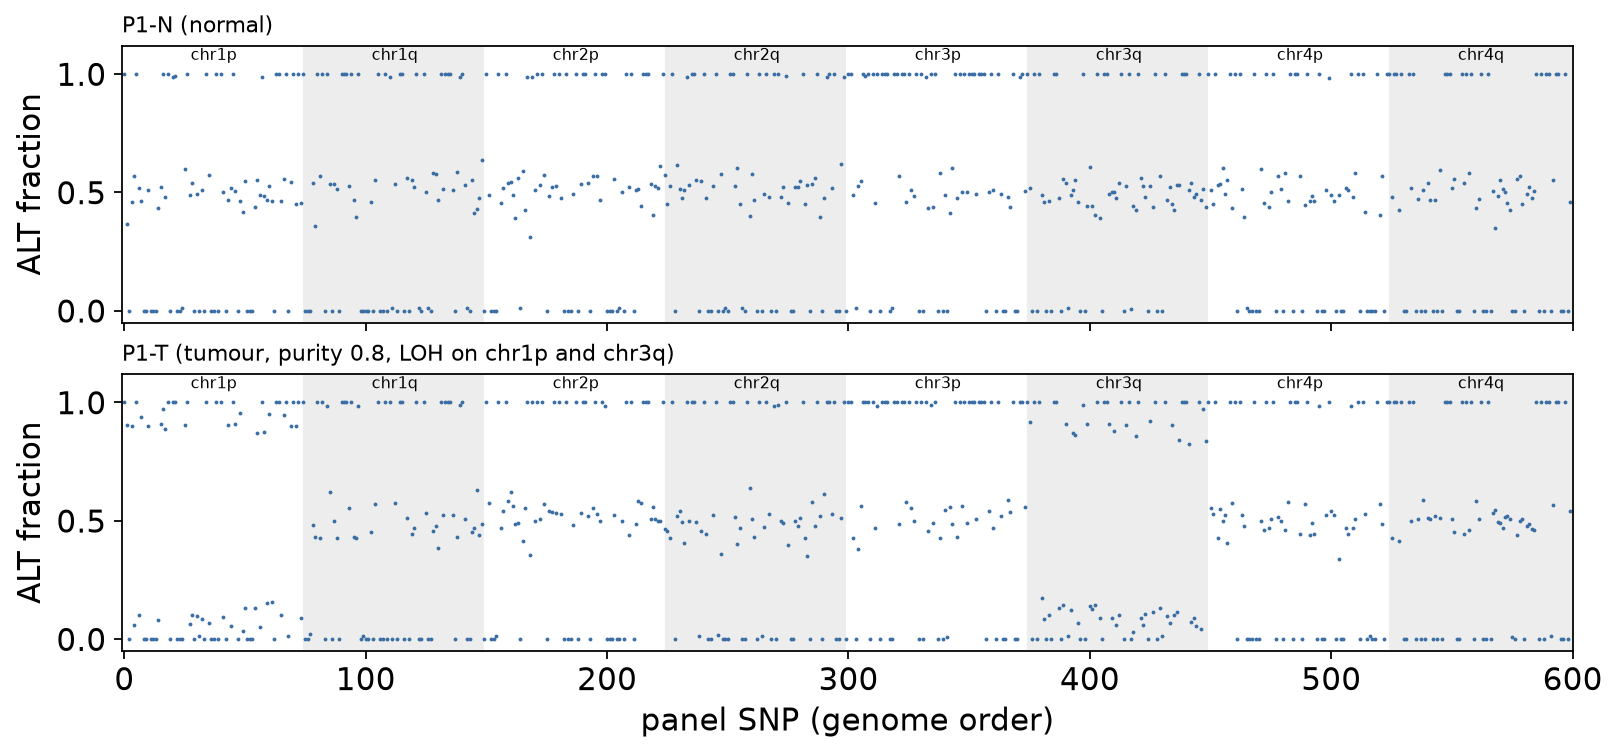

In [7]:
def baf_plot(ax, sample, title=None):
    d = counts[counts['sample'] == sample].reset_index(drop=True)
    regs = d['region_id'].values
    for k, r in enumerate(pd.unique(regs)):
        idx = np.flatnonzero(regs == r)
        ax.axvspan(idx[0] - 0.5, idx[-1] + 0.5, color='0.93' if k % 2 else 'white', zorder=0)
        ax.text(idx.mean(), 1.06, r, ha='center', fontsize=7)
    ax.scatter(d.index, d['alt_fraction'], s=3, c='#3a6ea5', lw=0)
    ax.set_ylim(-0.05, 1.12); ax.set_xlim(-1, len(d))
    ax.set_ylabel('ALT fraction'); ax.set_title(title or sample, loc='left', fontsize=10)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, constrained_layout=True)
baf_plot(axes[0], 'P1-N', 'P1-N (normal)')
baf_plot(axes[1], 'P1-T', 'P1-T (tumour, purity 0.8, LOH on chr1p and chr3q)')
axes[1].set_xlabel('panel SNP (genome order)')
plt.show()

## 4. Library-level QC — `bam_read_summary`

Before looking at genotypes, check that every library looks like its
batch. `bam_read_summary` reads the alignments inside the target
intervals and reports, per sample, primary read count, read-length
quantiles and N50, mean MAPQ, duplicate / secondary / supplementary
fractions and the fraction of reads carrying modified-base tags (`MM`/`ML`,
for nanopore / PacBio methylation calls). Each metric gets a **robust
z-score** (median / MAD across the batch, log scale for lengths and counts),
and |z| ≥ `outlier_z` (3.5) is listed in `outliers`. Robust statistics
matter here: one degraded library must not inflate the spread that is
used to detect it.

In [8]:
rs = ov.genetics.bam_read_summary(f'{outdir}/bams', targets=f'{outdir}/targets.bed')
rs[['sample', 'primary_reads', 'median_read_length', 'read_n50', 'mean_mapq',
    'duplicate_fraction', 'z_median_read_length', 'outliers']].round(2)

        sample  primary_reads  median_read_length  read_n50  mean_mapq  \
0   P1-N-rerun          46307               137.0     138.0       60.0   
1         P1-N          52500               151.0     153.0       60.0   
2         P1-T          42140               152.0     153.0       60.0   
3         P2-N          49452               142.0     144.0       60.0   
4         P2-T          33554               146.0     148.0       60.0   
5         P3-N          47162               146.0     147.0       60.0   
6         P3-T          32033               146.0     147.0       60.0   
7         P4-N          40444                75.0      78.0       60.0   
8         P4-T          52891               147.0     148.0       60.0   
9         P5-N          36160               139.0     140.0       60.0   
10        P5-T          44213               146.0     147.0       60.0   
11        P6-N          47773               140.0     141.0       60.0   
12        P6-T          46606         

`P4-N` is the only flagged library: its median read length (~75 bp) is
many robust standard deviations below the batch (~145 bp) — the
signature of fragmented, e.g. FFPE-degraded, DNA. The other metrics are
constant across this simulated batch (MAPQ 60, no duplicates, no
modified-base tags), so their MAD is zero and no z-score is defined
(reported as 0). A library outlier is **ancillary**: it explains noisy
data but is not itself a genetic finding.

## 5. Who is who — `sample_genotype_concordance`

Two libraries from the same person share their germline genotype at
every SNP; two unrelated people disagree at a large fraction of common
SNPs. `sample_genotype_concordance` calls a genotype state at every site
with depth ≥ `min_depth` (AF ≤ 0.15 hom-ref, ≥ 0.85 hom-alt, 0.30–0.70
het; anything in between is *ambiguous and not compared*, so LOH,
contamination and low purity do not create false calls) and computes the
**discordance** of every ordered pair. By default it keeps only
**germline-informative** sites (`informative='shared'`): sites where both
alleles are seen at clonal fraction in at least two samples, so that
tumour-private (somatic) alleles cannot mask identity.

Every sample's comparators are ranked; a pair that is each other's best
match is `mutual_best` (same individual), and `gap_to_next` measures how
clearly the best match beats the runner-up.

In [9]:
conc = ov.genetics.sample_genotype_concordance(counts)
print('germline-informative sites:', conc.attrs['n_informative_sites'])
conc[conc['rank'] == 1][['sample', 'comparator', 'n_compared', 'discordance',
                         'opposite_hom', 'mutual_best', 'gap_to_next']].round(3)

germline-informative sites: 588


         sample  comparator  n_compared  discordance  opposite_hom  \
0          P1-N  P1-N-rerun         588        0.000             0   
12   P1-N-rerun        P1-N         588        0.000             0   
24         P1-T        P1-N         582        0.122             0   
25         P1-T  P1-N-rerun         582        0.122             0   
36         P2-N        P3-T         587        0.109             0   
48         P2-T        P3-N         560        0.139             0   
60         P3-N        P2-T         560        0.139             0   
72         P3-T        P2-N         587        0.109             0   
84         P4-N        P4-T         573        0.084             0   
96         P4-T        P4-N         573        0.084             0   
108        P5-N        P5-T         584        0.161             0   
120        P5-T        P5-N         584        0.161             0   
132        P6-N        P6-T         588        0.000             0   
144        P6-T     

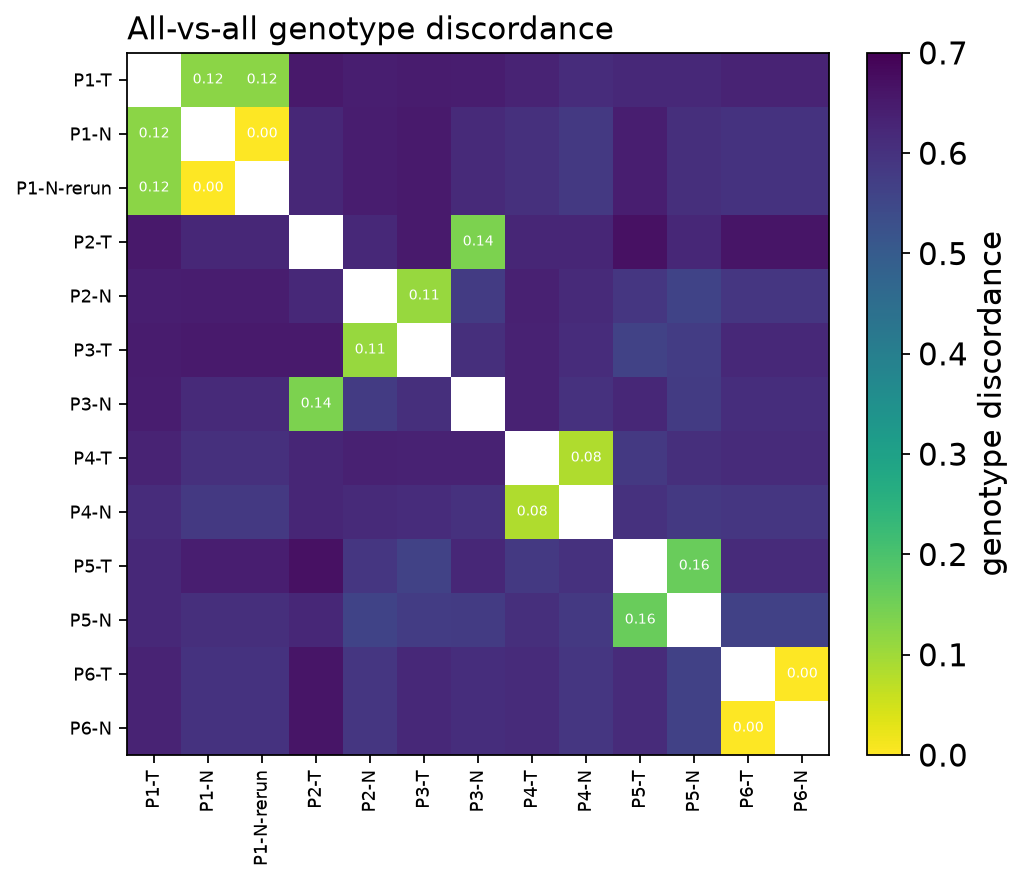

discordance, same individual  : 0.000 - 0.161
discordance, different people : 0.558 - 0.668


In [10]:
order = [s for p in range(1, 7) for s in (f'P{p}-T', f'P{p}-N', f'P{p}-N-rerun') if s in COMPOSITION]
M = conc.pivot(index='sample', columns='comparator', values='discordance').reindex(index=order, columns=order)
fig, ax = plt.subplots(figsize=(6.4, 5.4), constrained_layout=True)
im = ax.imshow(M.values, cmap='viridis_r', vmin=0, vmax=0.7)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8)
ax.set_yticks(range(len(order)), order, fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        v = M.values[i, j]
        if np.isfinite(v) and v < 0.2:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6.5, color='white')
fig.colorbar(im, ax=ax, label='genotype discordance')
ax.set_title('All-vs-all genotype discordance', loc='left')
plt.show()

ind_of = {s: max(COMPOSITION[s].items(), key=lambda kv: kv[1])[0][1] for s in COMPOSITION}  # true individual
same = conc['sample'].map(ind_of) == conc['comparator'].map(ind_of)
print('discordance, same individual  : %.3f - %.3f' % (conc.loc[same, 'discordance'].min(), conc.loc[same, 'discordance'].max()))
print('discordance, different people : %.3f - %.3f' % (conc.loc[~same, 'discordance'].min(), conc.loc[~same, 'discordance'].max()))

The heatmap is a block diagram of individuals. Unrelated pairs disagree
at 56–67 % of the informative sites; same-person pairs at 0 (two
normals) to ~0.16 (tumour vs normal — the residual comes from the LOH
arms, where a tumour's heterozygous sites look homozygous). The two
ranges are separated by a wide gap, which is what makes identity calls
safe. Three things stand out:

- `P1-T`, `P1-N` and `P1-N-rerun` form one block — the re-sequenced
  library is recognised as the **same individual** (discordance ≈ 0 with
  `P1-N`), as planted;
- `P2-T` matches `P3-N`, and `P3-T` matches `P2-N` — **not** their own
  submitted normals: the **swap**;
- every other tumour is paired with its submitted normal.

## 6. Check the manifest — `resolve_sample_relationships`

The concordance table says who matches whom; the manifest says who
*should*. `resolve_sample_relationships` checks every submitted
tumour / baseline record, reports the rank and discordance of the
submitted partner and the molecularly best comparator of each member,
and labels the record `SUPPORTED` (the submitted pair is the same
individual) or `MISMATCH`.

In [11]:
rel = ov.genetics.resolve_sample_relationships(conc, manifest, case_col='case_id',
                                               a_col='tumor_alias', b_col='submitted_baseline_alias')
rel[['case_id', 'a', 'b', 'submitted_rank_for_a', 'submitted_discordance',
     'best_for_a', 'best_for_a_discordance', 'best_for_b', 'status']].round(3)

  case_id     a     b  submitted_rank_for_a  submitted_discordance best_for_a  \
0      P1  P1-T  P1-N                     1                  0.122       P1-N   
1      P2  P2-T  P2-N                     2                  0.620       P3-N   
2      P3  P3-T  P3-N                     4                  0.606       P2-N   
3      P4  P4-T  P4-N                     1                  0.084       P4-N   
4      P5  P5-T  P5-N                     1                  0.161       P5-N   
5      P6  P6-T  P6-N                     1                  0.000       P6-N   

   best_for_a_discordance  best_for_b     status  
0                   0.122  P1-N-rerun   MISMATCH  
1                   0.139        P3-T   MISMATCH  
2                   0.109        P2-T   MISMATCH  
3                   0.084        P4-T  SUPPORTED  
4                   0.161        P5-T  SUPPORTED  
5                   0.000        P6-T  SUPPORTED  

Cases `P2` and `P3` are `MISMATCH`: the submitted normal ranks far down
the list for its tumour (discordance ~0.5, i.e. an unrelated person),
and the proposed repairs (`best_for_a`, `best_for_b`) are exactly the
planted swap — `P2-T` ↔ `P3-N` and `P3-T` ↔ `P2-N`. In practice this is
where you stop and fix the sample sheet: every somatic call of `P2` and
`P3` made against the submitted normals would be germline noise. The
downstream checks below use the **repaired** pairing automatically.

But `P1` — the clean control — is *also* `MISMATCH`, although
`best_for_a` is its own normal. The reason is the re-sequenced library.
Same-individual groups are built from **mutual-best** pairs: `P1-N` and
`P1-N-rerun` are each other's best match (discordance 0), while `P1-T`
ties between the two (identical discordance); `P1-T` is the best match of neither,
so it is linked to nobody. Two libraries of the same sample must
therefore be **pooled (or one dropped) before the review** — which is
also what you would do before somatic calling. Pooling is a sum of the
allele counts per site:

In [12]:
key = ['sample', 'chrom', 'pos', 'ref', 'alt', 'region_id', 'in_target']
pooled = counts.assign(sample=counts['sample'].replace({'P1-N-rerun': 'P1-N'}))
counts_qc = pooled.groupby(key, as_index=False, sort=False)[['ref_count', 'alt_count', 'other_count', 'depth']].sum()
counts_qc['alt_fraction'] = counts_qc['alt_count'] / counts_qc['depth'].where(counts_qc['depth'] > 0)
counts_qc = counts_qc[counts.columns]
conc = ov.genetics.sample_genotype_concordance(counts_qc)
rel = ov.genetics.resolve_sample_relationships(conc, manifest)
rel[['case_id', 'a', 'b', 'submitted_discordance', 'best_for_a', 'best_for_b', 'status']].round(3)

  case_id     a     b  submitted_discordance best_for_a best_for_b     status
0      P1  P1-T  P1-N                  0.120       P1-N       P1-T  SUPPORTED
1      P2  P2-T  P2-N                  0.621       P3-N       P3-T   MISMATCH
2      P3  P3-T  P3-N                  0.608       P2-N       P2-T   MISMATCH
3      P4  P4-T  P4-N                  0.084       P4-N       P4-T  SUPPORTED
4      P5  P5-T  P5-N                  0.161       P5-N       P5-T  SUPPORTED
5      P6  P6-T  P6-N                  0.000       P6-N       P6-T  SUPPORTED

With one `P1-N` (now at twice the depth) `P1` is `SUPPORTED`, and the
only mismatches left are the planted swap. From here on we work with the
pooled table `counts_qc`.

## 7. Cross-sample contamination — `estimate_cross_sample_contamination`

At a site where a sample is homozygous, every read of the other allele
is either a sequencing error or foreign DNA. If the foreign DNA comes
from a sample of the same batch, those minority reads appear
**preferentially at the sites where that sample carries the allele**.
The function turns that into a model: at each affected sample's
homozygous-like sites (minor AF < 0.25, depth ≥ 8) the minority count is

$$k_i \sim \mathrm{Bin}\Big(n_i,\; \varepsilon + \sum_S a_S\, s_{S,i}\Big),\qquad a_S \ge 0,$$

where $s_{S,i}$ is the frequency of that allele in candidate source $S$
and $\varepsilon$ is the background error. All sources are fitted
**jointly** (maximum likelihood); each source's evidence is the
likelihood ratio of dropping it, corrected for over-dispersion and
Bonferroni-corrected over all ordered pairs. Sites whose minority allele
no batch sample carries (somatic variants, artefacts) are removed from the
fit. This is the batch-internal analogue of VerifyBamID's population
mixture model, and it names the **source**, not only the fraction.

Two options make it tumour-aware (the batch QC in section 10 sets them
for you): `genotype_reference` restricts a tumour's sites to loci that are
homozygous in its *individual* (tumour **and** matched normal), so LOH
loci, where the residual minority reads are the tumour's own normal
cells, do not confound a foreign source; `groups` tests a foreign
individual's samples together, because a person's tumour and normal are
genetically collinear as sources.

In [13]:
samples_qc = sorted(counts_qc['sample'].unique())
groups = {s: [x for x in samples_qc if x.split('-')[0] == s.split('-')[0]] for s in samples_qc}
# the swap is repaired: the normal that is really P2's is the P3-N file, and vice versa
groups.update({'P2-T': ['P2-T', 'P3-N'], 'P3-N': ['P2-T', 'P3-N'],
               'P3-T': ['P3-T', 'P2-N'], 'P2-N': ['P3-T', 'P2-N']})
gref = {'P1-T': ['P1-N'], 'P2-T': ['P3-N'], 'P3-T': ['P2-N'],
        'P4-T': ['P4-N'], 'P5-T': ['P5-N'], 'P6-T': ['P6-N']}
cont = ov.genetics.estimate_cross_sample_contamination(counts_qc, genotype_reference=gref, groups=groups)
cols = ['affected', 'source', 'fraction', 'lr', 'p_adj', 'called', 'informative_sites',
        'hit_sites', 'private_markers', 'source_individual']
cont[cols].head(8).round(4)

  affected source  fraction        lr   p_adj  called  informative_sites  \
0     P4-T   P6-T    0.0468  460.8300  0.0000    True                218   
1     P4-T   P6-N    0.0463  460.8300  0.0000   False                218   
2     P4-N   P2-N    0.0018   14.2222  0.0107   False                213   
3     P4-N   P3-T    0.0020   14.2222  0.0107   False                187   
4     P1-T   P2-N    0.0014    5.9274  0.9839   False                216   
5     P1-T   P3-T    0.0012    5.9274  0.9839   False                196   
6     P5-N   P1-N    0.0015    5.5844  1.0000   False                206   
7     P5-N   P1-T    0.0014    5.5844  1.0000   False                179   

   hit_sites  private_markers source_individual  
0        196                0         P6-N,P6-T  
1        196                0         P6-N,P6-T  
2         21                1         P2-N,P3-T  
3         21                0         P2-N,P3-T  
4         21                1         P2-N,P3-T  
5         19   

Reading the table:

- The only **foreign** call is `P4-T ← P6-N` at an estimated fraction
  close to the planted **5 %**, with an enormous likelihood ratio and
  minority reads at most of the loci where `P6-N` carries the allele
  that individual 4 lacks (`hit_sites` / `informative_sites`).
  `source_individual` lists `P6-N,P6-T`: the two samples of individual
  6 are tested together (one likelihood ratio for the individual), and
  the call goes to the member whose single-source fit is best; the other
  is reported, uncalled, as an alternate. Here the two fit equally well —
  at purity 0.15 `P6-T` is genetically almost a normal — so the
  attribution within individual 6 is a coin toss, while the attribution
  *to individual 6* is unambiguous. The planted source was `P6-N`; read
  the `comparison` column of the batch review as "this person", not "this
  file".
- No tumour is "contaminated" by its own normal, although every tumour
  here contains 15–25 % normal cells. That is the effect of
  `genotype_reference`: at loci homozygous in the *individual* the
  normal cells add no minority allele. Without it, the LOH loci (where
  the tumour looks homozygous but its normal cells still carry the lost
  allele) would make the tumour's own normal look like a source — that
  is tumour content, not contamination, and `tumor_normal_batch_qc`
  never reports it as contamination.

The figure shows the raw evidence: at loci homozygous in individual 4,
the minority-allele fraction of `P4-T` grouped by the genotype of `P6-N`
at that allele.

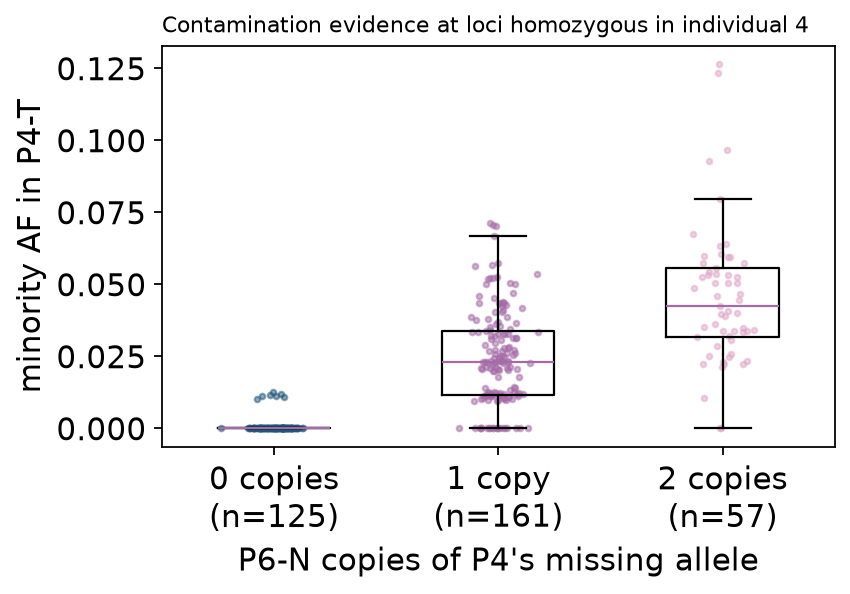

In [14]:
wide_af = counts_qc.pivot_table(index=['chrom', 'pos'], columns='sample', values='alt_fraction')
wide_dp = counts_qc.pivot_table(index=['chrom', 'pos'], columns='sample', values='depth')
g4 = wide_af[['P4-T', 'P4-N']].mean(1)
hom4 = ((wide_af['P4-N'] < 0.1) | (wide_af['P4-N'] > 0.9)) & (wide_dp['P4-T'] >= 8)
minor_alt = g4 < 0.5
minor_T = np.where(minor_alt, wide_af['P4-T'], 1 - wide_af['P4-T'])[hom4]
src_state = np.where(minor_alt, wide_af['P6-N'], 1 - wide_af['P6-N'])[hom4]
state = pd.cut(src_state, [-0.01, 0.15, 0.85, 1.01], labels=['0 copies', '1 copy', '2 copies'])
fig, ax = plt.subplots(figsize=(5.2, 3.6), constrained_layout=True)
data = [minor_T[state == k] for k in state.categories]
ax.boxplot(data, showfliers=False, widths=0.5)
for k, d in enumerate(data, 1):
    ax.scatter(np.full(len(d), k) + rng.normal(0, 0.06, len(d)), d, s=6, alpha=0.5)
ax.set_xticks([1, 2, 3], [f'{c}\n(n={len(d)})' for c, d in zip(state.categories, data)])
ax.set_xlabel("P6-N copies of P4's missing allele"); ax.set_ylabel('minority AF in P4-T')
ax.set_title('Contamination evidence at loci homozygous in individual 4', loc='left', fontsize=10)
plt.show()

When `P6-N` carries no copy of the missing allele, `P4-T` shows only
sequencing error (~0.1 %); with one copy the minority fraction rises to
≈ 0.05 × 0.5 = 2.5 %, with two copies to ≈ 5 %. This dose–response is
exactly the mixture model, and it is why the method can name the source
— a contamination of a few percent never produces a genotype call, so
concordance alone would miss it.

## 8. Loss of heterozygosity and tumour content — `tumor_normal_allelic_imbalance`

At SNPs where the **normal** is heterozygous (|AF − 0.5| ≤ 0.2), fold the
allele fraction, $f = \min(\mathrm{AF}, 1-\mathrm{AF})$. A balanced region
keeps $f \approx 0.5$ in the tumour; copy-neutral LOH in a fraction
$p$ of cells pulls it to $0.5\,(1-p)$. Per region the function reports

$$\text{imbalance} = 1 - \frac{\operatorname{median} f_T}{\operatorname{median} f_N},$$

with a one-sided Mann–Whitney test (tumour folded AF lower than normal).
For a clonal copy-neutral LOH the imbalance **equals the tumour
content**, so the deepest significant region gives a purity estimate
(`tumor_content_estimate`). A tumour in which no region reaches
`clonal_imbalance` (0.5) is flagged `low_tumor_content`.

In [15]:
reg1, summ1 = ov.genetics.tumor_normal_allelic_imbalance(counts_qc, 'P1-T', 'P1-N')
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in summ1.items()})
reg1.round(3)

{'tumor': 'P1-T', 'normal': 'P1-N', 'het_loci': 265, 'median_folded_tumor': 0.442, 'median_folded_normal': 0.476, 'median_folded_shift': 0.039, 'max_imbalance': 0.799, 'max_imbalance_region': 'chr1p', 'tumor_content_estimate': 0.799, 'imbalanced_regions': ['chr1p', 'chr1q', 'chr3p', 'chr3q'], 'loh_regions': ['chr1p', 'chr3q'], 'loh_loci': 77, 'low_tumor_content': False}


  region_id  het_loci  median_folded_tumor  median_folded_normal  imbalance  \
0     chr1p        34                0.094                 0.470      0.799   
1     chr1q        28                0.448                 0.478      0.062   
2     chr2p        36                0.469                 0.479      0.020   
3     chr2q        34                0.471                 0.475      0.008   
4     chr3p        24                0.456                 0.476      0.043   
5     chr3q        43                0.097                 0.473      0.795   
6     chr4p        34                0.470                 0.479      0.018   
7     chr4q        32                0.478                 0.474     -0.010   

   p_value  imbalanced  
0    0.000        True  
1    0.006        True  
2    0.125       False  
3    0.209       False  
4    0.010        True  
5    0.000        True  
6    0.011       False  
7    0.503       False  

For `P1-T` the two arms with **clonal** imbalance (`loh_regions`,
imbalance ≥ 0.5) are exactly the planted LOH arms (`chr1p`, `chr3q`), and
the imbalance there (~0.8) is the planted purity of 0.8.

Note, however, that `imbalanced_regions` also lists `chr1q` and `chr3p`
with a tiny imbalance (≤ 0.06) at p < 0.01, although nothing was planted
there. This is a **depth artefact** worth understanding: the folded AF
$\min(\mathrm{AF}, 1-\mathrm{AF})$ of a heterozygote is biased below 0.5
by sampling noise, and more so at lower depth. After pooling, `P1-N` has
~160× and `P1-T` ~70×, so the tumour's folded AF is systematically a bit
lower everywhere and a rank test with ~30 loci picks that up. The
`clonal_imbalance` threshold is what keeps such shifts out of the LOH
calls; treat isolated small "imbalances" between libraries of very
different depth with suspicion. Let us run every tumour against its matched
normal — using the **repaired** pairs for `P2`/`P3` — and compare with the
truth.

In [16]:
pairs = {'P1-T': 'P1-N', 'P2-T': 'P3-N', 'P3-T': 'P2-N', 'P4-T': 'P4-N', 'P5-T': 'P5-N', 'P6-T': 'P6-N'}
imb_rows, imb_mat = [], {}
for t, n in pairs.items():
    reg, summ = ov.genetics.tumor_normal_allelic_imbalance(counts_qc, t, n)
    ind = 'I' + t[1]
    imb_mat[t] = reg.set_index('region_id')['imbalance']
    imb_rows.append({'tumour': t, 'matched_normal': n, 'true_purity': PURITY[ind],
                     'tumor_content_estimate': summ['tumor_content_estimate'],
                     'true_LOH': ','.join(sorted(LOH[ind])), 'called_LOH': ','.join(sorted(summ['loh_regions'])),
                     'low_tumor_content': summ['low_tumor_content']})
pd.DataFrame(imb_rows).round(3)

  tumour matched_normal  true_purity  tumor_content_estimate  \
0   P1-T           P1-N         0.80                   0.799   
1   P2-T           P3-N         0.75                   0.775   
2   P3-T           P2-N         0.85                   0.856   
3   P4-T           P4-N         0.80                   0.773   
4   P5-T           P5-N         0.85                   0.863   
5   P6-T           P6-N         0.15                   0.080   

            true_LOH         called_LOH  low_tumor_content  
0        chr1p,chr3q        chr1p,chr3q              False  
1  chr1q,chr2p,chr4q  chr1q,chr2p,chr4q              False  
2        chr2q,chr3p        chr2q,chr3p              False  
3        chr1q,chr4p        chr1q,chr4p              False  
4  chr1p,chr2q,chr4p  chr1p,chr2q,chr4p              False  
5        chr3q,chr4q                                  True  

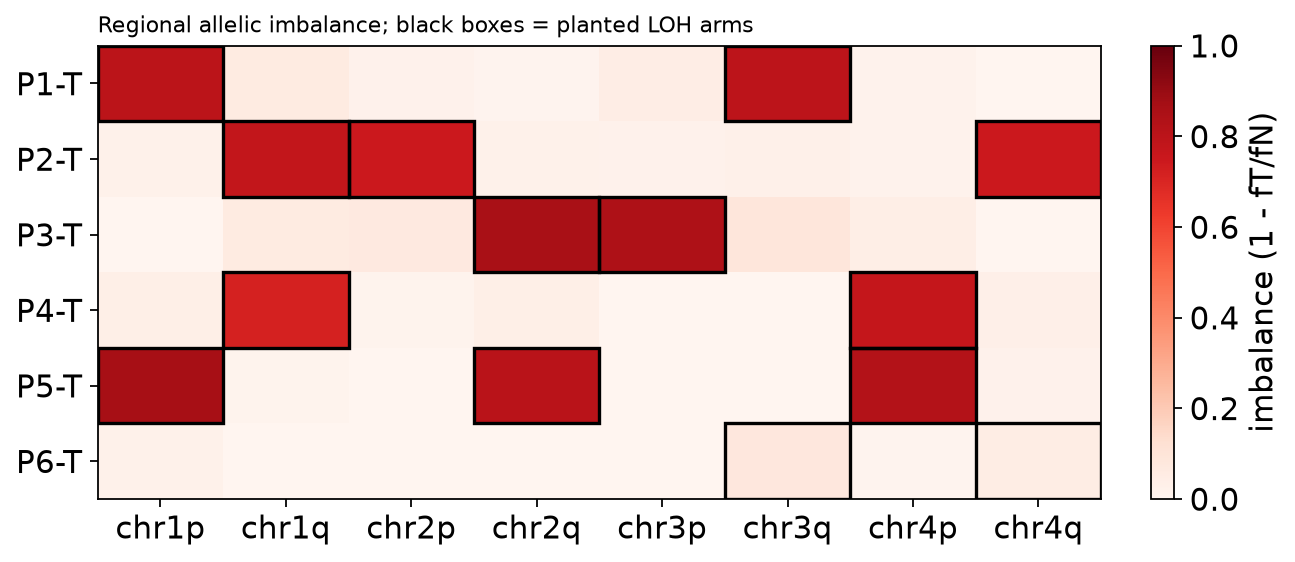

P6-T imbalance on its LOH arms: {'chr3q': 0.08, 'chr4q': 0.049}


In [17]:
I = pd.DataFrame(imb_mat).T.reindex(columns=targets['name'])
fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
im = ax.imshow(I.values, cmap='Reds', vmin=0, vmax=1, aspect='auto')
for r, t in enumerate(I.index):
    for c, reg_name in enumerate(I.columns):
        if reg_name in LOH['I' + t[1]]:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec='k', lw=1.5))
ax.set_xticks(range(I.shape[1]), I.columns); ax.set_yticks(range(I.shape[0]), I.index)
fig.colorbar(im, ax=ax, label='imbalance (1 - fT/fN)')
ax.set_title('Regional allelic imbalance; black boxes = planted LOH arms', loc='left', fontsize=10)
plt.show()
print('P6-T imbalance on its LOH arms:', I.loc['P6-T', LOH['I6']].round(3).to_dict())

Every planted LOH arm lights up and nothing else does, with an
imbalance that tracks each tumour's purity (0.75–0.85 estimated vs
0.75–0.85 planted). The exception is `P6-T`: its LOH arms (`chr3q`,
`chr4q`) show an imbalance of only 0.05–0.08 — even below the planted
purity of 0.15, because the folding of noisy allele fractions compresses
small shifts — far below the 0.5 needed for a clonal LOH, so the
function flags it as **low tumour content** and no LOH region is
returned. The BAF plot shows why: a 15 %-pure tumour is almost
indistinguishable from its normal.

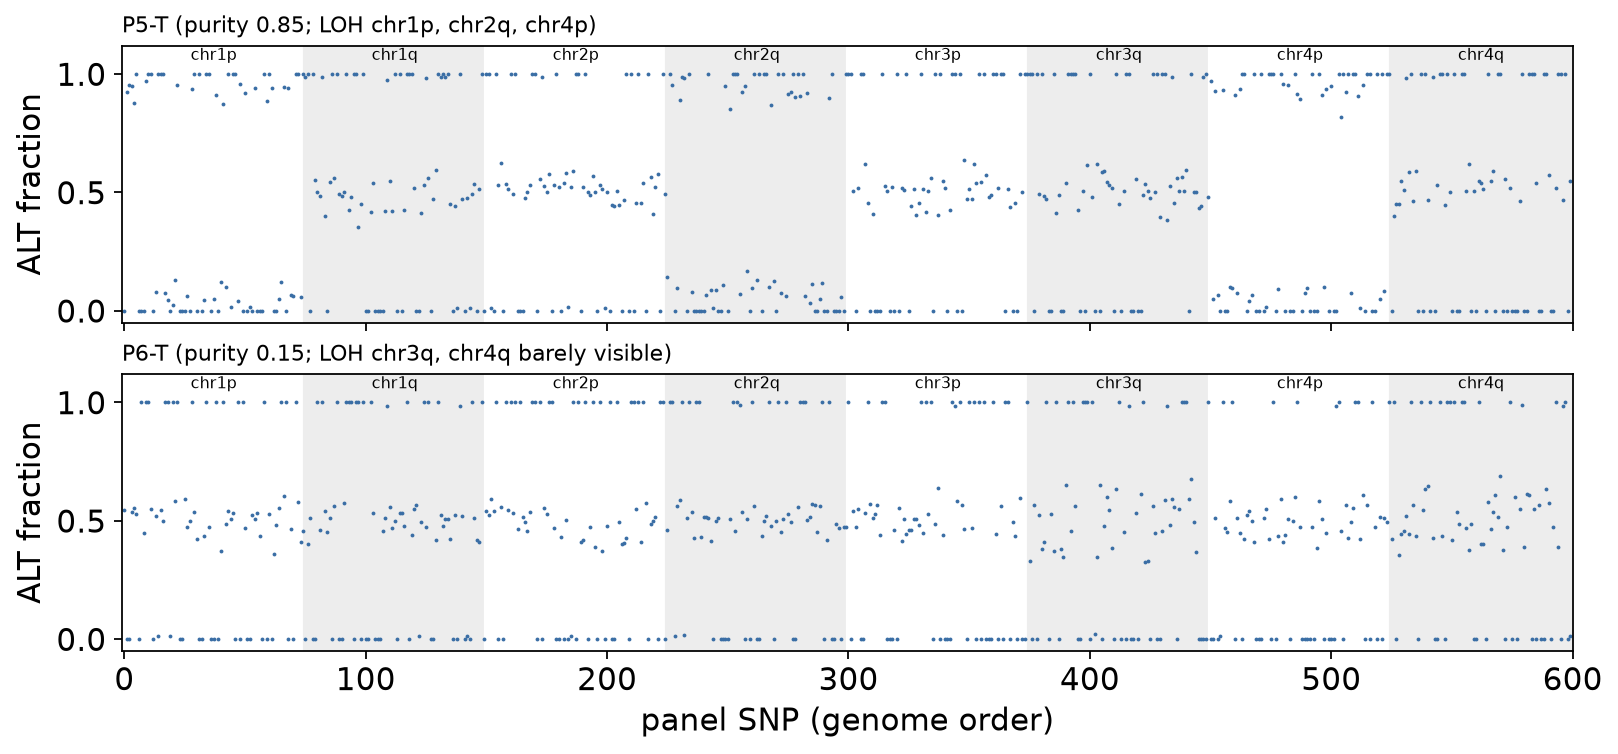

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, constrained_layout=True)
baf_plot(axes[0], 'P5-T', 'P5-T (purity 0.85; LOH chr1p, chr2q, chr4p)')
baf_plot(axes[1], 'P6-T', 'P6-T (purity 0.15; LOH chr3q, chr4q barely visible)')
axes[1].set_xlabel('panel SNP (genome order)')
plt.show()

## 9. Tumour cells in the normal — `tumor_in_normal_shift`

Tumour-in-normal contamination is invisible to the contamination model
when the panel has only germline SNPs: the tumour carries no allele
that the normal lacks. It is visible inside the **tumour's LOH
regions**: there the tumour has kept one allele, so tumour cells in the
normal pull the normal's heterozygous AF from 0.5 toward that retained
allele, $\mathrm{AF}_N = 0.5 + f\,(\mathrm{AF}_T - 0.5)$.

`tumor_in_normal_shift` takes the normal-heterozygous loci inside the
tumour's LOH regions where the tumour clearly retains one allele, and
averages the signed shift $d = (\mathrm{AF}_N - 0.5)\cdot\operatorname{sign}(\mathrm{AF}_T - 0.5)$
**separately** over ALT-retained and REF-retained loci. A reference
mapping bias would push both groups in opposite directions and cancels in
the average — this is the direction-balanced design. It returns a z-score,
a one-sided p-value and the implied tumour-derived fraction `f`. A tumour
without LOH gives `tested=False`: no power, which is *not* evidence of a
clean normal.

In [19]:
tin = pd.DataFrame([ov.genetics.tumor_in_normal_shift(counts_qc, t, n) for t, n in pairs.items()])
tin[['tumor', 'normal', 'tested', 'loci_alt_retained', 'loci_ref_retained',
     'shift', 'z', 'p_value', 'fraction']].round(4)

  tumor normal  tested  loci_alt_retained  loci_ref_retained   shift       z  \
0  P1-T   P1-N    True                 31                 46  0.0018  0.3858   
1  P2-T   P3-N    True                 59                 49  0.0030  0.5192   
2  P3-T   P2-N    True                 39                 27 -0.0156 -2.3337   
3  P4-T   P4-N    True                 25                 39 -0.0040 -0.4774   
4  P5-T   P5-N    True                 45                 52  0.0462  7.8922   
5  P6-T   P6-N   False                  0                  0     NaN     NaN   

   p_value  fraction  
0   0.3498    0.0044  
1   0.3018    0.0079  
2   0.9902   -0.0367  
3   0.6835   -0.0106  
4   0.0000    0.1096  
5   1.0000       NaN  

Only `P5-N` shows a significant shift (z well above 4), with an
estimated tumour-derived fraction near the planted **10 %** (the
fraction is relative to the `P5-T` *sample*, which is itself 85 %
tumour). The other normals have |z| < 2.5 — and the test is one-sided, so
a negative z (as for `P2-N`) is simply no evidence. `P6-T` is not tested: at 15 %
purity it keeps no allele clearly enough (|AF_T − 0.5| ≥ 0.25) to give
the test any power.

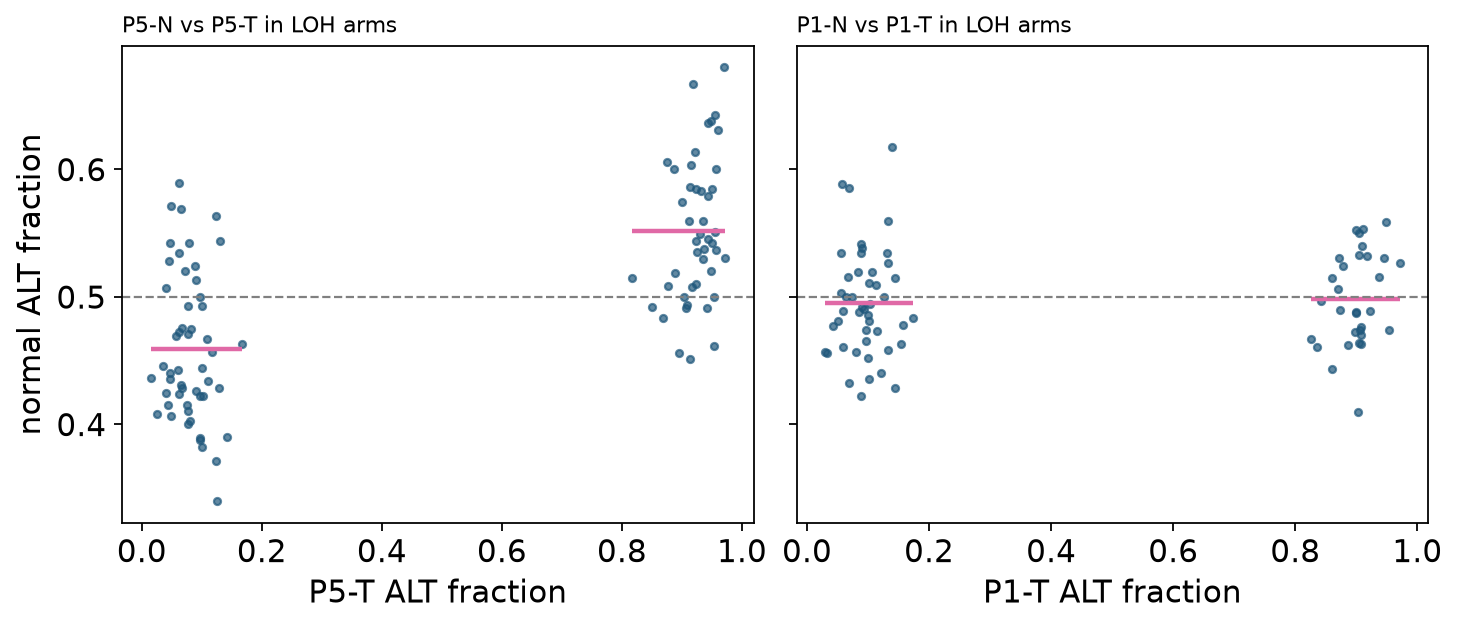

In [20]:
d = counts_qc.pivot_table(index=['chrom', 'pos'], columns='sample', values='alt_fraction')
rg = counts_qc.drop_duplicates(['chrom', 'pos']).set_index(['chrom', 'pos'])['region_id'].reindex(d.index)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True, constrained_layout=True)
for ax, (t, n) in zip(axes, [('P5-T', 'P5-N'), ('P1-T', 'P1-N')]):
    m = rg.isin(LOH['I' + t[1]]) & ((d[n] - 0.5).abs() <= 0.25) & ((d[t] - 0.5).abs() >= 0.25)
    ax.scatter(d.loc[m, t], d.loc[m, n], s=10, alpha=0.7)
    for side in (d[t] > 0.5, d[t] < 0.5):
        mm = m & side
        ax.hlines(d.loc[mm, n].mean(), d.loc[mm, t].min(), d.loc[mm, t].max(), color='C3', lw=2)
    ax.axhline(0.5, color='0.5', ls='--', lw=1)
    ax.set_xlabel(f'{t} ALT fraction'); ax.set_title(f'{n} vs {t} in LOH arms', loc='left', fontsize=10)
axes[0].set_ylabel('normal ALT fraction')
plt.show()

In the contaminated normal (left) the red group means sit above 0.5 at
ALT-retained loci and below 0.5 at REF-retained loci — the normal leans
toward whatever the tumour kept. In the clean `P1-N` (right) both means
sit on 0.5.

## 10. One call for the whole batch — `tumor_normal_batch_qc`

`tumor_normal_batch_qc` runs sections 5–9 in the right order and with
the right coupling:

1. concordance → same-individual groups → manifest check
   (`identity_mismatch`);
2. matched normal of each tumour **after repair** of mismatches;
3. contamination with `genotype_reference` / `groups` set from step 2;
   normal admixture of a tumour is reported as tumour content, a foreign
   source as `cross_sample_contamination`, a tumour source in its own
   normal as `tumor_in_normal`;
4. allelic imbalance per tumour (`low_tumor_content`) and the LOH-region
   shift test for tumour-in-normal (Bonferroni over tested pairs);
5. `library_outlier` from an optional `bam_read_summary` table.

It returns one row per supported finding, assigned to the case in which
the affected sample was submitted, plus all intermediate tables.

In [21]:
res = ov.genetics.tumor_normal_batch_qc(counts_qc, manifest, read_summary=rs)
findings = res['findings']
findings[['case_id', 'finding_type', 'affected', 'comparison', 'region_id',
          'support_loci', 'effect_size', 'confidence']]

  case_id                finding_type   affected comparison region_id  \
0      P2           identity_mismatch  P2-T,P2-N  P3-N,P3-T  MULTIPLE   
1      P3           identity_mismatch  P3-T,P3-N  P2-N,P2-T  MULTIPLE   
2      P4  cross_sample_contamination       P4-T  P6-T,P6-N  MULTIPLE   
3      P4             library_outlier       P4-N         NA        NA   
4      P5             tumor_in_normal       P5-N       P5-T  MULTIPLE   
5      P6           low_tumor_content       P6-T       P6-N  MULTIPLE   

   support_loci  effect_size confidence  
0         559.0     0.620751       HIGH  
1         586.0     0.607509       HIGH  
2         196.0     0.046800       HIGH  
3           NaN    75.000000     MEDIUM  
4          97.0     0.109600       HIGH  
5         289.0     0.453000       HIGH  

In [22]:
for r in findings.itertuples():
    print(f'[{r.case_id}] {r.finding_type}: {r.evidence}\n')

[P2] identity_mismatch: submitted pair P2-T/P2-N genotype discordance 0.621 over 559 germline-informative loci (rank 2 for P2-T); best match of P2-T is P3-N (0.140), of P2-N is P3-T (0.109)

[P3] identity_mismatch: submitted pair P3-T/P3-N genotype discordance 0.608 over 586 germline-informative loci (rank 4 for P3-T); best match of P3-T is P2-N (0.109), of P3-N is P2-T (0.140)

[P4] cross_sample_contamination: estimated P6-T fraction in P4-T 0.047 (joint mixture LRT 460.8, adj p 2.1e-100); minority P6-T alleles at 196/218 homozygous P4-T loci, mean minor AF 0.033; 0 P6-T-private markers with 0 reads

[P4] library_outlier: P4-N read-level batch outlier: median_read_length(low, z=-16.2);read_n50(low, z=-20.7)

[P5] tumor_in_normal: P5-N heterozygous allele fraction shifted toward P5-T's retained alleles inside P5-T's LOH regions (chr1p,chr2q,chr4p): direction-balanced shift 0.046 over 45 ALT- and 52 REF-retained loci, z 7.9; estimated P5-T-derived fraction 0.110

[P6] low_tumor_content:

### Did we recover the planted truth?

In [23]:
truth = [('P1', None, None),   # clean control (its re-run library pooled in section 6)
         ('P2', 'identity_mismatch', 'P2-T,P2-N'), ('P3', 'identity_mismatch', 'P3-T,P3-N'),
         ('P4', 'cross_sample_contamination', 'P4-T'), ('P4', 'library_outlier', 'P4-N'),
         ('P5', 'tumor_in_normal', 'P5-N'), ('P6', 'low_tumor_content', 'P6-T')]
planted_value = {'cross_sample_contamination': 0.05, 'tumor_in_normal': 0.10}
rows = []
for case, ftype, aff in truth:
    hit = findings[(findings.case_id == case) & (findings.finding_type == ftype) & (findings.affected == aff)]
    if ftype is None:
        rows.append({'case': case, 'planted': 'nothing (clean control)', 'recovered': len(findings[findings.case_id == case]) == 0,
                     'estimate': '', 'truth': ''})
        continue
    est = hit['effect_size'].iloc[0] if len(hit) else np.nan
    rows.append({'case': case, 'planted': f'{ftype} ({aff})', 'recovered': len(hit) == 1,
                 'estimate': round(est, 3) if ftype in planted_value and len(hit) else '',
                 'truth': planted_value.get(ftype, '')})
check = pd.DataFrame(rows)
extra = findings[~findings.apply(lambda r: any(r.case_id == c and r.finding_type == f and r.affected == a
                                               for c, f, a in truth), axis=1)]
print('unexpected findings:', len(extra))
check

unexpected findings: 0


  case                            planted  recovered estimate truth
0   P1            nothing (clean control)       True               
1   P2      identity_mismatch (P2-T,P2-N)       True               
2   P3      identity_mismatch (P3-T,P3-N)       True               
3   P4  cross_sample_contamination (P4-T)       True    0.047  0.05
4   P4             library_outlier (P4-N)       True               
5   P5             tumor_in_normal (P5-N)       True     0.11   0.1
6   P6           low_tumor_content (P6-T)       True               

Every planted problem is reported once, on the right case and sample,
with the right partner in `comparison` (the swap partners for `P2`/`P3`,
individual 6 for the contamination of `P4-T`, `P5-T` for the tumour-in-normal),
and the clean control `P1` — including its extra re-sequenced library —
produces no finding. The contamination and tumour-in-normal fractions are
recovered close to their planted values.

`res` also carries everything the findings are built from:
`res['relationships']`, `res['contamination']`, `res['imbalance']` (one
row per tumour with LOH, purity and TiN statistics) and `res['groups']`
(the inferred same-individual sets).

In [24]:
res['imbalance'][['case_id', 'tumor', 'normal', 'het_loci', 'tumor_content_estimate', 'loh_regions',
                  'low_tumor_content', 'normal_admixture_fraction', 'tin_z', 'tin_fraction']].round(3)

  case_id tumor normal  het_loci  tumor_content_estimate  \
0      P1  P1-T   P1-N       265                   0.799   
1      P2  P2-T   P3-N       283                   0.775   
2      P3  P3-T   P2-N       252                   0.856   
3      P4  P4-T   P4-N       257                   0.773   
4      P5  P5-T   P5-N       269                   0.863   
5      P6  P6-T   P6-N       289                   0.080   

             loh_regions  low_tumor_content  normal_admixture_fraction  tin_z  \
0         [chr1p, chr3q]              False                        0.0  0.386   
1  [chr1q, chr2p, chr4q]              False                        0.0  0.519   
2         [chr2q, chr3p]              False                        0.0 -2.334   
3         [chr1q, chr4p]              False                        0.0 -0.477   
4  [chr1p, chr2q, chr4p]              False                        0.0  7.892   
5                     []               True                        0.0    NaN   

   tin_frac

## 11. Pitfalls

- **Depth.** Genotype states need depth: at 8× (the default
  `min_depth`) a heterozygote is called as homozygous ~4 % of the time.
  Contamination below ~1 % and tumour-in-normal below a few percent need
  tens of reads per SNP and hundreds of informative SNPs. Low-pass
  whole-genome data should use many more panel sites, not lower
  thresholds.
- **Unequal depth between tumour and normal.** Folded allele fractions
  are biased toward 0 by sampling noise, more at lower depth, so a
  shallow tumour against a deep normal shows small, "significant"
  imbalance everywhere (section 8). Rely on `loh_regions` (the clonal
  threshold), not on `imbalanced_regions` alone, or down-sample the
  deeper library.
- **Duplicate libraries.** Same-individual groups come from mutual-best
  pairs, so two libraries of the same sample make the tumour's best
  match a tie and break the group (section 6). Pool or drop re-runs
  before `tumor_normal_batch_qc`.
- **Panel choice.** The panel must be **common** SNPs (MAF ≳ 0.1 in the
  cohort's ancestry). Rare SNPs are homozygous in almost everyone and
  carry no identity or source information. Remove sites in segmental
  duplications or with known mapping problems — paralogous reads create
  "heterozygous" sites in everyone.
- **Related individuals.** First-degree relatives share ~50 % of
  alleles and have intermediate discordance; a relative's normal can be
  the best match of a tumour whose own normal is missing. Always read
  `gap_to_next` and the absolute discordance, not only the rank.
- **Tumour biology is not a QC failure.** LOH lowers tumour–normal
  concordance; widespread LOH, whole-genome doubling or a very
  hypermutated tumour can push a true pair toward the mismatch range.
  The `'shared'` informative-site filter and the ambiguous-AF band are
  there for this reason — do not set `informative='all'` for tumours.
- **Reference bias.** Aligners favour the reference allele, so
  heterozygous AF sits slightly below 0.5. `tumor_in_normal_shift` cancels
  it by balancing ALT- and REF-retained loci; a one-sided "AF > 0.5"
  test would not.
- **Purity vs imbalance.** `tumor_content_estimate` equals purity only
  for a *clonal, copy-neutral* LOH. Single-copy deletions (one allele at
  copy number 1) and sub-clonal events give smaller imbalance for the same
  purity, so treat it as a lower bound; dedicated tools (ASCAT, FACETS)
  fit copy number and purity jointly.
- **No LOH, no TiN test.** A tumour without LOH gives `tested=False`; that
  means the panel cannot see tumour-in-normal, not that the normal is
  clean. Somatic-marker methods (deTiN) need the tumour's mutations.
- **Contamination sources outside the batch.** The mixture model only
  knows the samples you give it. Contamination from a sample of another
  batch inflates the background error and the dispersion instead of
  producing a named source; a population-frequency model (VerifyBamID2,
  Conpair) estimates such a fraction without naming the source.

## 12. References

- Lee S. *et al.* (2017). NGSCheckMate: software for validating sample
  identity in next-generation sequencing studies within and across data
  types. *Nucleic Acids Research* 45(11):e103.
  [doi:10.1093/nar/gkx193](https://doi.org/10.1093/nar/gkx193)
- Bergmann E. A., Chen B.-J., Arora K., Vacic V., Zody M. C. (2016).
  Conpair: concordance and contamination estimator for matched
  tumor–normal pairs. *Bioinformatics* 32(20):3196–3198.
  [doi:10.1093/bioinformatics/btw389](https://doi.org/10.1093/bioinformatics/btw389)
- Jun G. *et al.* (2012). Detecting and estimating contamination of human
  DNA samples in sequencing and array-based genotype data. *American
  Journal of Human Genetics* 91(5):839–848.
  [doi:10.1016/j.ajhg.2012.09.004](https://doi.org/10.1016/j.ajhg.2012.09.004)
- Zhang F. *et al.* (2020). Ancestry-agnostic estimation of DNA sample
  contamination from sequence reads (VerifyBamID2). *Genome Research*
  30(2):185–194. [doi:10.1101/gr.246934.118](https://doi.org/10.1101/gr.246934.118)
- Taylor-Weiner A. *et al.* (2018). DeTiN: overcoming tumor-in-normal
  contamination. *Nature Methods* 15(7):531–534.
  [doi:10.1038/s41592-018-0036-9](https://doi.org/10.1038/s41592-018-0036-9)
- Van Loo P. *et al.* (2010). Allele-specific copy number analysis of
  tumors (ASCAT). *PNAS* 107(39):16910–16915.
  [doi:10.1073/pnas.1009843107](https://doi.org/10.1073/pnas.1009843107)
- Li H. *et al.* (2009). The Sequence Alignment/Map format and SAMtools.
  *Bioinformatics* 25(16):2078–2079.
  [doi:10.1093/bioinformatics/btp352](https://doi.org/10.1093/bioinformatics/btp352)